# La compuerta de integridad que respalda el corpus, y los controles que hacen que el motor se niegue

**Pregunta:** ¿Detecta la compuerta de carga un error de transcripción, y qué capa detecta cuál?

**Nivel 4: Más allá del estado del arte** · Requiere: 01-the-data/01-the-corpus-and-the-cases, 01-the-data/02-geometry-reconstruction · Tiempo de lectura: unos 30 minutos

## Objetivos

Una tabla copiada de un artículo vale lo que vale la copia, y una celda errónea no se anuncia: los predictores la ajustan y devuelven números. Fragmenta pone dos resguardos alrededor de sus datos: una compuerta que corre en cada carga del corpus (afirmación BS-3) y una regla de negativa para tiros que ningún predictor debería valorar (afirmación BS-2). Este notebook prueba ambos como lo haría un escéptico, plantando errores y mirando qué responde.

Al terminar, usted habrá:

- recalculado los 28 estadísticos que imprime el artículo desde las filas distribuidas y visto cuánto margen da la compuerta a cada uno;
- plantado seis defectos realistas en copias del corpus, uno por celda, y sondeado cada capa de la compuerta por separado para cada uno;
- leído qué capa detecta qué defecto y cuánto mueve cada defecto a un estadístico impreso, y visto qué hacen los defectos aguas abajo cuando nadie revisa;
- preguntado a doce predictores por un sitio que no tiene escala y por seis diseños que no son tiros, y visto quién responde.

## Preparación

Instale los paquetes con las versiones exactas de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación siguiente importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número, agrega al camino de importación la carpeta `data-pipeline/` del producto (allí vive la guarda de diseño del Paso 7), fija el estilo de los gráficos y define `show_table`, un ayudante de cuatro líneas que dibuja filas como tabla Markdown porque el entorno de notebooks no tiene `pandas`.

In [1]:
# Importaciones, versiones, ruta al pipeline, estilo y ayudante de tablas
import dataclasses
import sys
from decimal import Decimal
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.colors import ListedColormap

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

sys.path.insert(0, str(Path("../../../data-pipeline")))
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Dibujar las filas como tabla Markdown, las primeras `left` columnas a la izquierda y las demás a la derecha
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

Dos fuentes, y no se lee ningún archivo de `data/`: los controles corren en vivo.

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Las 97 filas, los 28 estadísticos descriptivos impresos y el resumen criptográfico fijado | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | la tabla, `PUBLISHED_DESCRIPTIVE_STATS` y `DATASET_DIGEST` dentro del paquete `blastfrag` |
| El registro de casos y la guarda de diseño | este repositorio (MIT) | la licencia propia del producto | `data-pipeline/pipeline/registry.py` y `data-pipeline/pipeline/model/blasts.py`, importados por ruta |

## Método

La compuerta que corre dentro de `load_training_corpus()` tiene dos capas independientes, y responden preguntas distintas.

1. **Los estadísticos impresos.** El artículo imprime un mínimo, un máximo, una media y una desviación estándar para cada una de las siete entradas. La compuerta recalcula los 28 desde las filas distribuidas y compara cada uno con la precisión con que se imprimió. Una discrepancia significa que el archivo ya no es la tabla publicada.
2. **El resumen criptográfico del contenido.** Un estadístico es un testigo débil de una sola celda cambiada: corregir un factor de carga mueve una media sobre 97 filas en menos que un paso de redondeo. Un resumen SHA-256 de toda la tabla, fijado en el motor, detecta cualquier cambio.

Ambas capas las llama `check_source_integrity` (Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 imprime los estadísticos). Los dos pasos siguientes abren una capa cada uno.

### Paso 1: la capa de estadísticos

El artículo imprime 28 números: cuatro estadísticos para cada una de siete entradas. La compuerta los recalcula desde las filas distribuidas y compara cada uno con la precisión con que se imprimió: media unidad del último dígito impreso para un mínimo o un máximo, una unidad para una media o una desviación estándar (las tolerancias que aplica el motor, repetidas aquí como `ALLOWANCE`). La celda carga el corpus, llama a la compuerta, recalcula los 28 estadísticos con una función pequeña que las celdas posteriores reutilizan, y los presenta junto a los valores impresos con la diferencia relativa y el margen relativo de cada uno.

In [2]:
# Recalcular los estadísticos de cada entrada y compararlos con los impresos
train = bf.load_training_corpus()
# Unidades del último dígito impreso que admite la compuerta
ALLOWANCE = {"minimum": 0.5, "maximum": 0.5, "mean": 1.0, "sd": 1.0}


def recomputed_statistics(rows):
    # (entrada, estadístico, impreso, recalculado, margen) de los 28 estadísticos
    result = []
    for name, printed in bf.PUBLISHED_DESCRIPTIVE_STATS.items():
        values = np.array([getattr(b, name) for b in rows])
        found = {"minimum": values.min(), "maximum": values.max(), "mean": values.mean(), "sd": values.std(ddof=1)}
        for statistic, value in found.items():
            shown = getattr(printed, statistic)
            places = -Decimal(str(shown)).as_tuple().exponent
            result.append((name, statistic, shown, value, ALLOWANCE[statistic] * 10.0**-places))
    return result


bf.check_source_integrity(train)
print("compuerta sobre el corpus distribuido: aprobada")
statistics = recomputed_statistics(train)
rows = []
for name, statistic, shown, value, allow in statistics:
    rows.append((name, statistic, shown, f"{value:.4f}", f"{abs(value - shown) / shown:.2%}", f"{allow / shown:.2%}"))
header = ["entrada", "estadístico", "el artículo imprime", "recalculado",
          "diferencia relativa", "margen"]
show_table(header, rows, left=2)

compuerta sobre el corpus distribuido: aprobada


| entrada | estadístico | el artículo imprime | recalculado | diferencia relativa | margen |
|:---|:---|---:|---:|---:|---:|
| S_over_B | minimum | 1.0 | 1.0000 | 0.00% | 5.00% |
| S_over_B | maximum | 1.75 | 1.7500 | 0.00% | 0.29% |
| S_over_B | mean | 1.19 | 1.1890 | 0.09% | 0.84% |
| S_over_B | sd | 0.117 | 0.1168 | 0.20% | 0.85% |
| H_over_B | minimum | 1.33 | 1.3300 | 0.00% | 0.38% |
| H_over_B | maximum | 6.82 | 6.8200 | 0.00% | 0.07% |
| H_over_B | mean | 3.34 | 3.3452 | 0.15% | 0.30% |
| H_over_B | sd | 1.634 | 1.6337 | 0.02% | 0.06% |
| B_over_D | minimum | 17.98 | 17.9800 | 0.00% | 0.03% |
| B_over_D | maximum | 39.47 | 39.4700 | 0.00% | 0.01% |
| B_over_D | mean | 27.35 | 27.3549 | 0.02% | 0.04% |
| B_over_D | sd | 4.838 | 4.8386 | 0.01% | 0.02% |
| T_over_B | minimum | 0.5 | 0.5000 | 0.00% | 10.00% |
| T_over_B | maximum | 4.67 | 4.6700 | 0.00% | 0.11% |
| T_over_B | mean | 1.26 | 1.2628 | 0.22% | 0.79% |
| T_over_B | sd | 0.674 | 0.6739 | 0.02% | 0.15% |
| Pf_kg_m3 | minimum | 0.22 | 0.2200 | 0.00% | 2.27% |
| Pf_kg_m3 | maximum | 1.26 | 1.2600 | 0.00% | 0.40% |
| Pf_kg_m3 | mean | 0.53 | 0.5292 | 0.16% | 1.89% |
| Pf_kg_m3 | sd | 0.236 | 0.2355 | 0.23% | 0.42% |
| XB_m | minimum | 0.02 | 0.0200 | 0.00% | 25.00% |
| XB_m | maximum | 2.35 | 2.3500 | 0.00% | 0.21% |
| XB_m | mean | 1.1 | 1.1067 | 0.61% | 9.09% |
| XB_m | sd | 0.533 | 0.5323 | 0.14% | 0.19% |
| E_GPa | minimum | 9.57 | 9.5700 | 0.00% | 0.05% |
| E_GPa | maximum | 60.0 | 60.0000 | 0.00% | 0.08% |
| E_GPa | mean | 29.46 | 29.4606 | 0.00% | 0.03% |
| E_GPa | sd | 17.879 | 17.8788 | 0.00% | 0.01% |

La compuerta pasa, y la tabla muestra cómo. Los mínimos y los máximos se reproducen exactamente. Las medias y las desviaciones estándar difieren de los valores impresos hasta en 0,61 por ciento (la media del tamaño de bloque in situ, que el artículo imprime como 1,1 y las filas dan como 1,1067), siempre dentro del margen que da el último dígito impreso. Los márgenes difieren enormemente, porque los fija cuántos dígitos imprimió el artículo: un mínimo impreso como 0,02 puede diferir en 25 por ciento, mientras que la media del módulo, impresa con cuatro cifras significativas, puede diferir en 0,03 por ciento. Así que la lección de la tabla no es el aprobado sino el margen: un defecto solo puede esconderse dentro del margen del estadístico que toca.

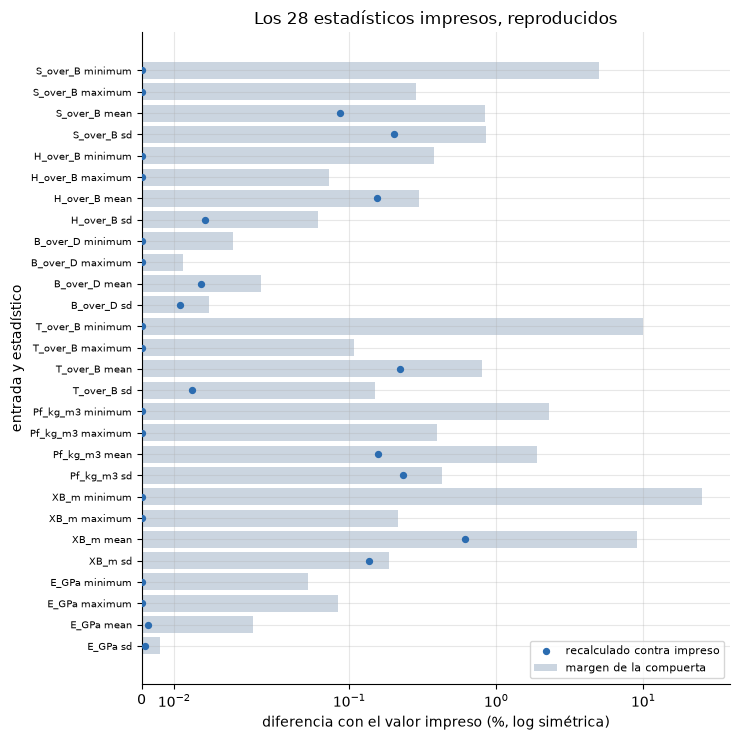

mayor diferencia como parte de su margen: 73%


In [3]:
# Diferencia de cada estadístico (punto) frente al margen de la compuerta (barra)
labels = [f"{name} {statistic}" for name, statistic, *_ in statistics]
difference = [abs(value - shown) / shown * 100 for _, _, shown, value, _ in statistics]
allowed = [allow / shown * 100 for _, _, shown, _, allow in statistics]
positions = np.arange(len(statistics))
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.barh(positions, allowed, color="#cbd5e0", label="margen de la compuerta")
ax.scatter(difference, positions, s=18, color="#2b6cb0", zorder=3, label="recalculado contra impreso")
ax.set_xscale("symlog", linthresh=0.05)
ax.set_yticks(positions, labels, fontsize=7)
ax.invert_yaxis()
ax.set_ylabel("entrada y estadístico")
ax.set_xlabel("diferencia con el valor impreso (%, log simétrica)")
ax.set_title("Los 28 estadísticos impresos, reproducidos")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
worst = max(abs(value - shown) / allow for _, _, shown, value, allow in statistics)
print("mayor diferencia como parte de su margen:", f"{worst:.0%}")

Cada barra es el margen de un estadístico y cada punto es la diferencia recalculada, en un eje logarítmico simétrico para que las coincidencias exactas (los puntos en cero) y las diferencias de unas centésimas de por ciento compartan una escala. Todo punto queda dentro de su barra, y el mayor está al 73 por ciento de su margen. Algunas barras son muy cortas: los estadísticos del módulo y los extremos de la razón bordo sobre diámetro tienen márgenes de centésimas de por ciento, así que un cambio allí se nota de inmediato, mientras que el mínimo del taco y el mínimo del tamaño de bloque, con márgenes de 10 y 25 por ciento, son casi ciegos. La figura muestra cuánto espacio deja cada estadístico para esconder un defecto; no dice qué defectos existen.

### Paso 2: la capa del resumen criptográfico

Un estadístico es un testigo débil: una celda cambiada entre 97 filas suele mover una media en menos que su margen. La segunda capa es un resumen SHA-256 de toda la tabla, fijado en el motor como `DATASET_DIGEST` y recalculado desde las filas por `compute_dataset_digest`. La celda muestra el resumen fijado, el de las filas distribuidas y el de una copia en la que se escribió mal un solo tamaño medido, y cuenta cuántos de los 64 dígitos hexadecimales cambiaron.

In [4]:
# La segunda capa: el resumen fijado, el de las filas y el de una celda editada
pinned = bf.datasets.DATASET_DIGEST
shipped = bf.datasets.compute_dataset_digest(train)
edited = [dataclasses.replace(b, x50_m=0.73) if b is train[0] else b for b in train]
changed = bf.datasets.compute_dataset_digest(edited)
rows = [("fijado en el motor", pinned[:20]), ("filas distribuidas", shipped[:20]),
        ("una celda editada: x50 de En1 0.37 escrito 0.73", changed[:20])]
show_table(["resumen", "SHA-256 (primeros 20 dígitos hex)"], rows)
print("distribuido igual a fijado:", shipped == pinned)
differ = sum(a != b for a, b in zip(shipped, changed))
print("dígitos hex que cambian tras la edición:", differ, "de", len(shipped))

| resumen | SHA-256 (primeros 20 dígitos hex) |
|:---|---:|
| fijado en el motor | 9a72094d641a2557be4f |
| filas distribuidas | 9a72094d641a2557be4f |
| una celda editada: x50 de En1 0.37 escrito 0.73 | b266b5621d79f4335ddb |

distribuido igual a fijado: True
dígitos hex que cambian tras la edición: 60 de 64


Las filas distribuidas reproducen el resumen fijado, y una celda mal escrita cambia 60 de los 64 dígitos hexadecimales: el resumen no mide similitud sino que es un sello que dice idéntico o distinto, nunca cuán distinto. Esa es su fuerza, porque detecta cualquier cambio, y su límite: no puede distinguir un cambio inocuo de uno dañino, y solo se puede fijar después de que alguien comparó la tabla con el artículo, que es lo que hace la capa de estadísticos. Las capas responden dos preguntas. Los estadísticos dicen que el archivo sigue siendo la tabla publicada; el resumen dice que no se ha movido desde entonces.

## Estado del arte

Tres hechos de la base de investigación del producto (el SDD) enmarcan lo que ya se sabe.

- El corpus es una tabla publicada. Hudaverdi, Kulatilake y Kuzu 2010 (https://doi.org/10.1002/nag.957) la imprimen junto con sus propios estadísticos resumen, lo que hace posible una verificación independiente.
- La base de investigación del SDD registra que una copia de la tabla guardada en la bóveda del laboratorio tenía cinco defectos de transcripción, dos de ellos en la variable objetivo, encontrados solo al comparar cada celda con las tablas del artículo. Un estudio que reutiliza una tabla copiada sin esa comparación hereda esos defectos en silencio.
- Los estudios que ajustan predictores aprendidos a estas filas (Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013; Sui et al. 2025, https://doi.org/10.3390/app15031254) reportan predictores de las siete entradas. Un regresor entrenado devuelve un número para cualquier vector de entrada y no tiene un dominio declarado en el que se niegue a responder, así que saber si un volumen de roca y una carga pueden conocerse para un tiro queda fuera de lo que ese predictor puede expresar.

La práctica habitual es entonces confiar en una tabla copiada y dejar que todo predictor responda todo. La sección siguiente mide lo que cuesta cada hábito.

## Más allá del estado del arte

Aquí se prueban dos afirmaciones, plantando errores y mirando qué responde.

**Afirmación BS-3, la compuerta de integridad en la carga.** Cada carga del corpus reproduce los estadísticos impresos del artículo y un resumen criptográfico fijado. La prueba planta seis defectos realistas, uno por celda, en copias del corpus y sondea cada capa por separado, y luego mide qué harían aguas abajo los defectos que pasan.

**Afirmación BS-2, la abstención como resultado de primera clase.** Un predictor que no puede conocer un volumen de roca debe decirlo en vez de responder. La prueba pregunta a doce predictores por el único sitio sin escala y por seis diseños que no son tiros.

### Paso 3: sondear cada capa por separado

`check_source_integrity` lanza una sola `ContractViolation` que lista todos los problemas que encontró. Para decir qué capa se activó, la celda define `statistics_complaint`, que llama a la compuerta con `check_digest=False` y devuelve su primera queja (o `None`), y revisa la capa del resumen comparando el resumen de las filas con el fijado. La primera sonda corre sobre el corpus limpio, donde ambas deben informar nada.

In [5]:
# Una sonda para la capa de estadísticos, por separado, y el resumen del corpus limpio
def statistics_complaint(rows):
    # La primera queja de la capa de estadísticos, o None si pasa
    try:
        bf.check_source_integrity(rows, check_digest=False)
    except bf.ContractViolation as violation:
        lines = str(violation).splitlines()
        return lines[1].strip() if len(lines) > 1 else lines[0]
    return None


planted = {}
print("capa de estadísticos sobre el corpus limpio:", statistics_complaint(train))
print("el resumen difiere en el corpus limpio:", bf.datasets.compute_dataset_digest(train) != pinned)

capa de estadísticos sobre el corpus limpio: None
el resumen difiere en el corpus limpio: False


En el corpus limpio la capa de estadísticos no tiene quejas y el resumen coincide con el fijado, así que cualquier queja que siga viene de un defecto plantado y no del instrumento.

### Defecto 1: el error histórico

La compuerta se escribió después de encontrar una copia de la tabla con un máximo del factor de carga de 1,47 donde el artículo imprime 1,26. La celda planta exactamente ese error en la fila con el mayor factor de carga y sondea ambas capas.

In [6]:
# Defecto 1: máximo del factor de carga escrito 1.47, el artículo imprime 1.26
label = "máximo del factor de carga 1.26 escrito como 1.47"
peak = max(train, key=lambda b: b.Pf_kg_m3)
planted[label] = [dataclasses.replace(b, Pf_kg_m3=1.47) if b is peak else b for b in train]
complaint = statistics_complaint(planted[label])
print("capa de estadísticos:", complaint or "pasa")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("resumen de la copia:", digest[:12], "| fijado:", pinned[:12], "| difiere:", digest != pinned)

capa de estadísticos: Pf_kg_m3.max: computed 1.470000, the source paper prints 1.26
resumen de la copia: 6e46ed378d83 | fijado: 9a72094d641a | difiere: True


La capa de estadísticos nombra el estadístico (`Pf_kg_m3.max`) y ambos números, el 1,47 calculado frente al 1,26 impreso, que es el mensaje más útil que puede dar la compuerta porque dice dónde mirar. El resumen también difiere, y dice solo que algo cambió.

### Defecto 2: un punto decimal perdido

El primer tiro, En1 de Enusa, tiene un módulo de la roca de 60,0 GPa, y un descuido escribe 6,0. El módulo es la única entrada que identifica una campaña, así que un valor erróneo aquí crearía en silencio una roca que no existe.

In [7]:
# Defecto 2: módulo de la roca 60.0 escrito como 6.0
label = "módulo 60.0 escrito como 6.0"
planted[label] = [dataclasses.replace(b, E_GPa=6.0) if b is train[0] else b for b in train]
complaint = statistics_complaint(planted[label])
print("capa de estadísticos:", complaint or "pasa")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("resumen de la copia:", digest[:12], "| fijado:", pinned[:12], "| difiere:", digest != pinned)

capa de estadísticos: E_GPa.min: computed 6.000000, the source paper prints 9.57
resumen de la copia: 00710021b249 | fijado: 9a72094d641a | difiere: True


La capa de estadísticos lo detecta en el mínimo: el mínimo calculado ahora es 6,0 mientras el artículo imprime 9,57. Un cambio de una década en el extremo de una entrada no puede esconderse, y el resumen también difiere.

### Defecto 3: un descuido en el segundo decimal

La razón de taco del primer tiro, 0,78, se escribe 0,79. Es el error de tipeo que todo lector comete y ninguno ve: un cambio de 0,01 en una celda de 97 filas.

In [8]:
# Defecto 3: razón de taco 0.78 escrita como 0.79
label = "razón de taco 0.78 escrita como 0.79"
planted[label] = [dataclasses.replace(b, T_over_B=0.79) if b is train[0] else b for b in train]
complaint = statistics_complaint(planted[label])
print("capa de estadísticos:", complaint or "pasa")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("resumen de la copia:", digest[:12], "| fijado:", pinned[:12], "| difiere:", digest != pinned)

capa de estadísticos: pasa
resumen de la copia: 91171a7ad249 | fijado: 9a72094d641a | difiere: True


La capa de estadísticos pasa: ningún estadístico impreso se mueve lo bastante para salir de su margen. Solo el resumen lo detecta. Aquí la capa de estadísticos no ve un defecto que sí existe, y la matriz siguiente mide el tamaño de esa brecha.

### Defecto 4: una medición transpuesta

El tamaño medido del primer tiro, 0,37 m, se escribe 0,73 m. Es la variable objetivo, el valor contra el que se puntúa todo predictor, así que es el defecto que más importa aguas abajo; pero el artículo no imprime ningún estadístico resumen del tamaño medido, de modo que nada en la capa de estadísticos puede verlo.

In [9]:
# Defecto 4: tamaño medido 0.37 escrito como 0.73
label = "tamaño medido 0.37 escrito como 0.73"
planted[label] = [dataclasses.replace(b, x50_m=0.73) if b is train[0] else b for b in train]
complaint = statistics_complaint(planted[label])
print("capa de estadísticos:", complaint or "pasa")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("resumen de la copia:", digest[:12], "| fijado:", pinned[:12], "| difiere:", digest != pinned)

capa de estadísticos: pasa
resumen de la copia: b266b5621d79 | fijado: 9a72094d641a | difiere: True


La capa de estadísticos pasa porque el tamaño medido no está entre los 28 estadísticos impresos, y solo el resumen detecta el cambio. El defecto más dañino de los seis es invisible para la capa construida con el resumen del propio artículo.

### Defecto 5: un tiro bajo la campaña equivocada

El primer tiro de Enusa se archiva bajo Reocin. Ningún número cambia, pero la campaña es la unidad que todo protocolo posterior deja fuera, así que una fila mal etiquetada pasa un tiro de una campaña a otra sin avisar.

In [10]:
# Defecto 5: un tiro archivado en la campaña equivocada
label = "tiro archivado en la campaña equivocada"
planted[label] = [dataclasses.replace(b, site="Reocin") if b is train[0] else b for b in train]
complaint = statistics_complaint(planted[label])
print("capa de estadísticos:", complaint or "pasa")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("resumen de la copia:", digest[:12], "| fijado:", pinned[:12], "| difiere:", digest != pinned)

capa de estadísticos: pasa
resumen de la copia: 7510e9063b32 | fijado: 9a72094d641a | difiere: True


La capa de estadísticos pasa, porque una etiqueta no es un estadístico, y el resumen lo detecta. Es el defecto que ningún resumen de los números podrá ver jamás.

### Defecto 6: una fila perdida

Una copia que perdió su primera fila tiene 96 tiros en lugar de 97, como ocurre cuando una tabla se pega desde una hoja de cálculo y se corta una línea.

In [11]:
# Defecto 6: una fila perdida en una copia
label = "una fila perdida"
planted[label] = train[1:]
complaint = statistics_complaint(planted[label])
print("capa de estadísticos:", complaint or "pasa")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("resumen de la copia:", digest[:12], "| fijado:", pinned[:12], "| difiere:", digest != pinned)

capa de estadísticos: the training corpus is 97 blasts, got 96
resumen de la copia: 1b4df22bcb89 | fijado: 9a72094d641a | difiere: True


La capa de estadísticos se detiene de inmediato con `the training corpus is 97 blasts, got 96`, antes de calcular ningún estadístico, porque el conteo de filas es lo primero que revisa la compuerta. El resumen también difiere.

### Paso 4: la matriz de detección

La celda sondea de nuevo las seis copias y reúne el veredicto de cada capa y de la compuerta completa. También mide cuánto mueve cada defecto a los 28 estadísticos impresos: para cada estadístico el cambio desde su valor limpio dividido por su margen, y el mayor de los 28. Un defecto que mueve algún estadístico más de un margen no puede esconderse de la capa de estadísticos; uno que no mueve nada tan lejos, sí.

In [12]:
# Matriz de detección: qué capa se activa y cuánto mueve cada defecto a los estadísticos
clean = {(n, s): value for n, s, _, value, _ in recomputed_statistics(train)}
matrix, movement = [], []
for label, copy in planted.items():
    statistics_layer = statistics_complaint(copy) is not None
    digest_layer = bf.datasets.compute_dataset_digest(copy) != pinned
    moved = max(abs(v - clean[(n, s)]) / allow for n, s, _, v, allow in recomputed_statistics(copy))
    matrix.append((statistics_layer, digest_layer, statistics_layer or digest_layer))
    movement.append(moved)
verdict = {True: "detectado", False: "no detectado"}
rows = []
for label, row, moved in zip(planted, matrix, movement):
    rows.append((label, *(verdict[v] for v in row), f"{moved:.2f}"))
header = ["defecto plantado", "capa de estadísticos", "capa del resumen",
          "compuerta completa", "mayor movimiento, en márgenes"]
show_table(header, rows)

| defecto plantado | capa de estadísticos | capa del resumen | compuerta completa | mayor movimiento, en márgenes |
|:---|---:|---:|---:|---:|
| máximo del factor de carga 1.26 escrito como 1.47 | detectado | detectado | detectado | 42.00 |
| módulo 60.0 escrito como 6.0 | detectado | detectado | detectado | 714.00 |
| razón de taco 0.78 escrita como 0.79 | no detectado | detectado | detectado | 0.07 |
| tamaño medido 0.37 escrito como 0.73 | no detectado | detectado | detectado | 0.00 |
| tiro archivado en la campaña equivocada | no detectado | detectado | detectado | 0.00 |
| una fila perdida | detectado | detectado | detectado | 184.26 |

La capa de estadísticos detectó tres de los seis, con buenas razones: los descuidos del factor de carga y del módulo movieron un estadístico impreso en 42 y 714 márgenes, y la fila perdida, además de fallar el conteo, movió estadísticos en 184. Los tres que no vio no movieron nada más allá de 0,07 márgenes (el descuido del taco) o nada en absoluto (el tamaño medido y la etiqueta de campaña, que ningún estadístico impreso involucra). La capa del resumen detectó los seis, y también la compuerta completa.

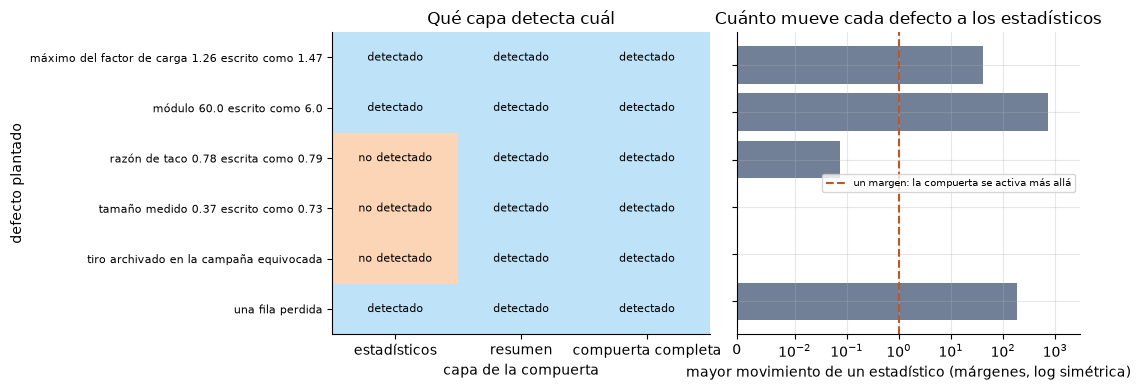

In [13]:
# Izquierda: qué capa se activa con cada defecto. Derecha: cuánto mueve un estadístico
names = list(planted)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.1, 1]})
left.imshow(np.array(matrix, dtype=float), cmap=ListedColormap(["#fbd5b5", "#bee3f8"]), aspect="auto")
for i, row in enumerate(matrix):
    for j, caught in enumerate(row):
        left.text(j, i, "detectado" if caught else "no detectado", ha="center", va="center", fontsize=8)
left.set_xticks(range(3), ["estadísticos", "resumen", "compuerta completa"])
left.set_yticks(range(len(names)), names, fontsize=8)
left.set_ylabel("defecto plantado")
left.set_xlabel("capa de la compuerta")
left.set_title("Qué capa detecta cuál")
left.grid(False)
right.barh(range(len(names)), movement, color="#718096")
right.axvline(1.0, color="#c05621", ls="--", label="un margen: la compuerta se activa más allá")
right.set_xscale("symlog", linthresh=0.01)
right.set_xlim(0, 3000)
right.set_yticks(range(len(names)), [""] * len(names))
right.invert_yaxis()
right.set_xlabel("mayor movimiento de un estadístico (márgenes, log simétrica)")
right.set_title("Cuánto mueve cada defecto a los estadísticos")
right.legend(fontsize=7, loc="center right")
fig.tight_layout()
plt.show()

El panel izquierdo es la matriz: la columna del resumen está llena mientras la de estadísticos tiene tres huecos, así que las capas no son redundantes, y la compuerta completa hereda el alcance del resumen. El panel derecho dice por qué, en un eje logarítmico simétrico: cada barra es el mayor movimiento de un estadístico impreso en márgenes, y la línea punteada en un margen es donde se activa la capa de estadísticos. Los tres defectos detectados quedan muy más allá, el descuido del taco queda en 0,07, y los defectos del tamaño medido y de la etiqueta de campaña no tienen barra porque no mueven ningún estadístico impreso. La figura no muestra cuántos otros defectos podrían escaparse a las capas; muestra que estos seis las separan.

### Paso 5: qué hacen aguas abajo los defectos que pasan

Si nadie corriera la compuerta, ¿alguien lo notaría? La celda ajusta la regresión reajustada del motor, una ley de potencia sobre las siete razones, con cada copia corrupta, predice con ella las 97 filas limpias, e informa el desplazamiento del tamaño medio del corpus y el mayor cambio en cualquier predicción frente a un ajuste con las filas limpias.

In [14]:
# Lo que vería quien usa una tabla copiada, aguas abajo de cada defecto
reference = np.array([p.x50_m for p in bf.RefittedRegression().fit(train).predict(train)])
rows = []
for label, copy in planted.items():
    predictions = np.array([p.x50_m for p in bf.RefittedRegression().fit(copy).predict(train)])
    shift = bf.training_mean(copy) - bf.training_mean(train)
    rows.append((label, f"{shift:+.4f}", f"{np.abs(predictions - reference).max():.4f}"))
header = ["defecto plantado", "desplazamiento del x50 medio (m)",
          "mayor cambio de predicción de una regresión reajustada (m)"]
show_table(header, rows)

| defecto plantado | desplazamiento del x50 medio (m) | mayor cambio de predicción de una regresión reajustada (m) |
|:---|---:|---:|
| máximo del factor de carga 1.26 escrito como 1.47 | +0.0000 | 0.0050 |
| módulo 60.0 escrito como 6.0 | +0.0000 | 0.0102 |
| razón de taco 0.78 escrita como 0.79 | +0.0000 | 0.0009 |
| tamaño medido 0.37 escrito como 0.73 | +0.0037 | 0.0578 |
| tiro archivado en la campaña equivocada | +0.0000 | 0.0000 |
| una fila perdida | -0.0007 | 0.0102 |

Los defectos que se escapan de los estadísticos son pequeños donde se escapan. El descuido del taco cambia una predicción reajustada en a lo más 0,0009 m, menos de un milímetro; la campaña mal etiquetada no cambia nada en una regresión sobre las razones; y el tamaño medido mal escrito mueve la media del corpus en 0,0037 m y una predicción en 0,0578 m. Nadie vería estas diferencias en un ajuste, y por eso mismo viajan. La fila reetiquetada es peor de lo que sugiere la tabla, pues cambiaría qué campaña quita un protocolo de exclusión, un efecto que ningún reajuste puede mostrar.

### Paso 6: el sitio sin escala

Un predictor que necesita un volumen de roca no debe responder donde no existe. El control de geometría son los seis tiros de Miami, a los que ninguna fuente da escala (notebook 02). La celda ajusta cada uno de los doce predictores (la escalera del motor sin sus dos controles, el modelo nulo y el oráculo) con las otras nueve campañas, le pregunta por los seis tiros de Miami, y cuenta para cada uno cuántos respondió y cuántos rechazó, con la primera razón que dio.

In [15]:
# Ajustar cada predictor con las otras nueve campañas y preguntarle por los seis tiros de Miami
miami = [b for b in train if b.site == "Miami"]
others = [b for b in train if b.site != "Miami"]
rows, reasons = [], {}
for name, build in bf.default_arms().items():
    if name in ("null", "oracle"):
        continue  # los dos controles no son predictores bajo prueba
    predictions = build().fit(others).predict(miami)
    refused = [p for p in predictions if p.x50_m is None]
    reasons[name] = refused[0].abstain_reason if refused else "-"
    rows.append((name, reasons[name][:58] + " ..." if refused else "-", len(predictions) - len(refused), len(refused)))
header = ["predictor", "primera razón de negativa", "respondió", "se negó"]
show_table(header, rows, left=2)
print("svr-poly, razón completa:", reasons["svr-poly"])

| predictor | primera razón de negativa | respondió | se negó |
|:---|:---|---:|---:|
| kuznetsov | Miami publishes no hole diameter, so rock volume and charg ... | 0 | 6 |
| kuznetsov-transfer | Miami publishes no hole diameter, so rock volume and charg ... | 0 | 6 |
| kuznetsov-capped | Miami publishes no hole diameter, so rock volume and charg ... | 0 | 6 |
| group-discriminant | this arm assigns a rock-stiffness group rather than a frag ... | 0 | 6 |
| published-regression | - | 6 | 0 |
| refitted-regression | - | 6 | 0 |
| published-neural-net | - | 6 | 0 |
| svr-rbf | - | 6 | 0 |
| svr-poly | the model returned -0.1446 m, which is outside the plausib ... | 3 | 3 |
| random-forest | - | 6 | 0 |
| xgboost | - | 6 | 0 |
| stacking | - | 6 | 0 |

svr-poly, razón completa: the model returned -0.1446 m, which is outside the plausible fragment range 0.001 to 3.0 m. This is the model leaving its domain, not a prediction.


Siete predictores responden los seis tiros de Miami, porque usan solo las razones y nunca necesitan una longitud. Los tres predictores clásicos rechazan los seis, con una razón que nombra el diámetro faltante. El discriminante de grupo rechaza los seis por otra razón, pues devuelve un grupo de rigidez de la roca y no un tamaño, una negativa por diseño. La regresión de vectores de soporte polinómica responde tres y rechaza tres, porque devolvió tamaños negativos fuera del rango plausible de 0,001 a 3 m. Así que una tabla contiene cuatro tipos de comportamiento, y cada negativa se explica sola. La tabla no dice que las siete respuestas sean correctas: no se pueden contrastar con una longitud que nadie publicó.

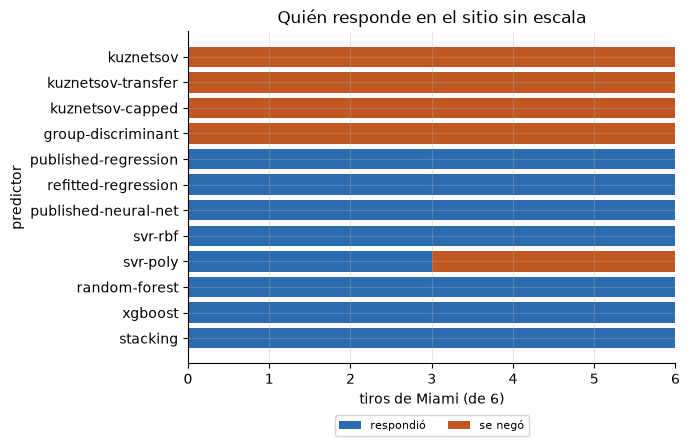

In [16]:
# Tiros de Miami respondidos y rechazados por cada predictor, de la tabla anterior
names = [row[0] for row in rows]
answered = np.array([row[2] for row in rows])
refused = np.array([row[3] for row in rows])
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(names, answered, color="#2b6cb0", label="respondió")
ax.barh(names, refused, left=answered, color="#c05621", label="se negó")
ax.invert_yaxis()
ax.set_xlabel("tiros de Miami (de 6)")
ax.set_ylabel("predictor")
ax.set_title("Quién responde en el sitio sin escala")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

Cada barra son los seis tiros de Miami de un predictor, azul donde respondió y naranja donde rechazó. Las cuatro barras totalmente naranjas son negativas, tres porque la escala se desconoce y una por diseño; la única barra partida, la regresión de vectores de soporte polinómica, es otro mecanismo, una guarda sobre la plausibilidad de la salida. La figura muestra qué tan selectiva es la negativa: el motor no se niega en todas partes, solo donde una respuesta sería una invención. No muestra si las respuestas azules merecen alguna confianza en un sitio que ninguna longitud puede verificar.

### Paso 7: diseños que no son tiros

El segundo control son seis diseños que no son tiros: un taco de 4,60 bordos en un banco de 1,40 bordos de alto no deja columna de carga. Un modelo ajustado sobre siete razones no sabe nada de esto y les dará precio. La celda carga los seis diseños desde el registro de casos del producto, ajusta cada uno de los doce predictores con el corpus completo y cuenta cuántos diseños valora cada uno al preguntarle directamente, y luego aplica la guarda de diseño del pipeline `is_degenerate` y cuenta de nuevo.

In [17]:
# Dar precio a seis diseños cuyo taco se traga el banco y aplicar la guarda del pipeline
from pipeline.model.blasts import blasts_for_case, is_degenerate
from pipeline.registry import get_case

designs = blasts_for_case(get_case("ctrl-degenerate"))
rows = []
for name, build in bf.default_arms().items():
    if name in ("null", "oracle"):
        continue
    predictions = build().fit(train).predict(designs)
    priced = sum(p.x50_m is not None for p in predictions)
    after = sum(p.x50_m is not None and is_degenerate(d) is None for p, d in zip(predictions, designs))
    rows.append((name, priced, after))
header = ["predictor", "diseños con precio directo (de 6)",
          "diseños con precio tras la guarda"]
show_table(header, rows)
print("diseños rechazados por la guarda:", sum(is_degenerate(d) is not None for d in designs), "de", len(designs))
for language in ("en", "es"):
    print(designs[0].blast_id, language, "-", is_degenerate(designs[0])[language])

| predictor | diseños con precio directo (de 6) | diseños con precio tras la guarda |
|:---|---:|---:|
| kuznetsov | 0 | 0 |
| kuznetsov-transfer | 6 | 0 |
| kuznetsov-capped | 0 | 0 |
| group-discriminant | 0 | 0 |
| published-regression | 6 | 0 |
| refitted-regression | 6 | 0 |
| published-neural-net | 6 | 0 |
| svr-rbf | 6 | 0 |
| svr-poly | 6 | 0 |
| random-forest | 6 | 0 |
| xgboost | 6 | 0 |
| stacking | 6 | 0 |

diseños rechazados por la guarda: 6 de 6
DG01 en - the stemming is 4.60 burdens in a bench 1.40 burdens tall, so there is no charge column. This is not a blast.
DG01 es - el taco mide 4,60 bordos en un banco de 1,40 bordos de alto, así que no hay columna de carga. Esto no es una voladura.


Nueve de los doce predictores dan precio a los seis diseños, entre ellos la regresión publicada, la red neuronal, el ensamble de apilamiento y la forma de transferencia de la ecuación clásica, que predice su propio factor de roca desde el módulo. Los tres que no responden lo hacen por accidente o por diseño: los dos predictores clásicos de factor constante por sitio no tienen factor para un sitio sintético, y el discriminante de grupo nunca devuelve un tamaño. Tras la guarda ningún predictor da precio a ningún diseño: la guarda rechaza los seis, y su razón, impresa arriba, está escrita en dos idiomas en el producto. Actúa sobre el diseño y no sobre el número, porque no hay un número que un modelo de razones rechazaría.

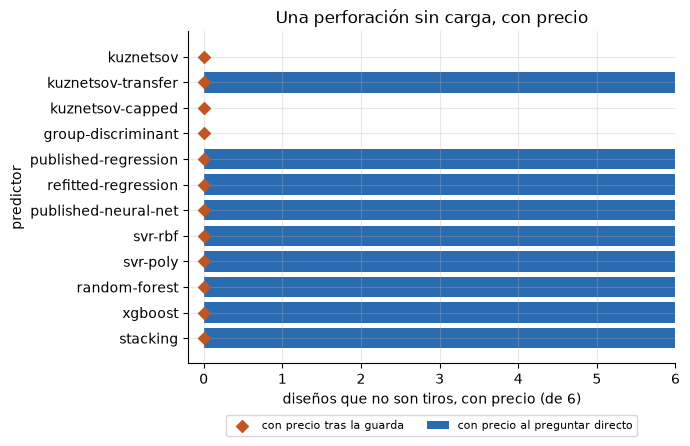

In [18]:
# Diseños con precio de cada predictor directo (barras) y tras la guarda (marcas)
names = [row[0] for row in rows]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(names, [row[1] for row in rows], color="#2b6cb0", label="con precio al preguntar directo")
ax.scatter([row[2] for row in rows], names, color="#c05621", marker="D", zorder=3, label="con precio tras la guarda")
ax.invert_yaxis()
ax.set_xlim(-0.2, len(designs))
ax.set_xlabel("diseños que no son tiros, con precio (de 6)")
ax.set_ylabel("predictor")
ax.set_title("Una perforación sin carga, con precio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

Las barras azules son los diseños a los que cada predictor da precio al preguntarle directamente, nueve de los doce con los seis completos; los rombos naranjas son lo que queda tras la guarda, cero para todo predictor. La figura muestra que negarse no es algo que la mayoría de los predictores haga por sí mismos: hay que agregarlo como una regla fuera de ellos. No muestra que la guarda detecte todo diseño que no sea un tiro. Prueba una regla, un taco que se traga el banco, y un diseño que falle de otra manera necesitaría otra regla.

## Resultados

**Respuesta:** Sí, pero solo con ambas capas juntas. Sobre las filas distribuidas la compuerta reproduce los 28 estadísticos impresos dentro de sus márgenes, el mayor al 73 por ciento de su margen, y el resumen fijado. De seis defectos plantados la capa de estadísticos detectó tres (los descuidos del factor de carga y del módulo, que movieron un estadístico impreso en 42 y 714 márgenes, y una fila perdida) y no vio tres (un descuido del taco, un tamaño medido mal escrito y una campaña mal etiquetada, que no movieron ningún estadístico más allá de 0,07 márgenes); la capa del resumen detectó los seis. La afirmación de negativa también se sostiene: cuatro de doce predictores rechazan los seis tiros de Miami, y tras la guarda del pipeline ninguno da precio a ninguno de los seis diseños que no son tiros, aunque nueve de los doce les dan precio cuando se les pregunta directamente.

**Qué se sigue.** Ninguna capa se puede omitir. Los estadísticos dicen que el archivo sigue siendo la tabla del artículo, y el resumen evita que se mueva después de esa comparación; una copia revisada solo con estadísticos pasa con una variable objetivo mal escrita. La negativa ante un diseño que no es un tiro es una regla fuera de los predictores, y cada nueva forma en que un diseño puede fallar necesita su propia regla.

**Lo que este notebook no muestra.** Pasar la compuerta muestra que el archivo es la tabla publicada, no que la tabla publicada acierte sobre los tiros. Los seis defectos son una muestra, no un censo de lo que puede salir mal. Y una negativa no prueba nada sobre la exactitud donde un predictor sí responde: los controles muestran que el motor se niega donde debe, no que acierte donde no se niega. Esa pregunta corresponde a los temas 04 y 05.

## Resumen

- La compuerta tiene dos capas: los 28 estadísticos impresos del artículo, comparados con la precisión con que se imprimieron, y un resumen SHA-256 fijado de toda la tabla (afirmación BS-3).
- Seis defectos plantados las separan: los estadísticos detectaron tres, el resumen detectó los seis, y los tres que solo ve el resumen incluyen el tamaño medido mal escrito.
- Los defectos que se escapan de los estadísticos desplazan una regresión reajustada en 0,0009 m, en nada o en 0,0578 m, diferencias que nadie notaría en un ajuste sin el resumen.
- De doce predictores, cuatro rechazan los seis tiros de Miami y, tras la guarda de diseño, ninguno da precio a ninguno de los seis diseños que no son tiros (afirmación BS-2).
- Siguiente: el tema 02 usa la geometría reconstruida para ejecutar la ecuación clásica.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (la tabla, sus estadísticos impresos, los defectos hallados por comparación)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (predictores aprendidos sobre las mismas filas)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (el ensamble de apilamiento y los tiros de campo)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/